In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!pip install -q kagglehub
import kagglehub
path = kagglehub.dataset_download("huberthamelin/garbage-classification-labels-corrections")
print(path)

100%|██████████| 497M/497M [00:06<00:00, 85.7MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/huberthamelin/garbage-classification-labels-corrections/versions/4


In [ ]:
import os
for dirpath, dirs, files in os.walk(path):
    imgs = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if imgs:
        print(os.path.basename(dirpath), len(imgs))

metal 837
battery 979
brown-glass 619
white-glass 796
shoes 2006
clothes 5286
biological 1035
green-glass 641
paper 1108
plastic 901
trash 726
cardboard 936
metal 767
battery 944
brown-glass 603
white-glass 764
shoes 2007
clothes 5286
biological 983
green-glass 613
paper 1043
plastic 864
trash 697
cardboard 896


In [ ]:
import os
for dirpath, dirs, files in os.walk(path):
    imgs = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if imgs:
        print(dirpath.replace(path, '') , len(imgs))

/garbage_classification_enhanced/metal 837
/garbage_classification_enhanced/battery 979
/garbage_classification_enhanced/brown-glass 619
/garbage_classification_enhanced/white-glass 796
/garbage_classification_enhanced/shoes 2006
/garbage_classification_enhanced/clothes 5286
/garbage_classification_enhanced/biological 1035
/garbage_classification_enhanced/green-glass 641
/garbage_classification_enhanced/paper 1108
/garbage_classification_enhanced/plastic 901
/garbage_classification_enhanced/trash 726
/garbage_classification_enhanced/cardboard 936
/garbage_classification_corrected/metal 767
/garbage_classification_corrected/battery 944
/garbage_classification_corrected/brown-glass 603
/garbage_classification_corrected/white-glass 764
/garbage_classification_corrected/shoes 2007
/garbage_classification_corrected/clothes 5286
/garbage_classification_corrected/biological 983
/garbage_classification_corrected/green-glass 613
/garbage_classification_corrected/paper 1043
/garbage_classificati

In [ ]:
import os, hashlib
from collections import defaultdict

DATA_DIR = os.path.join(path, "garbage_classification_enhanced")
class_names = sorted(os.listdir(DATA_DIR))
print(len(class_names), class_names)

IMG_EXT = (".jpg", ".jpeg", ".png")
hashes = defaultdict(list)
for c in class_names:
    for f in os.listdir(os.path.join(DATA_DIR, c)):
        if f.lower().endswith(IMG_EXT):
            p = os.path.join(DATA_DIR, c, f)
            with open(p, "rb") as fh:
                hashes[hashlib.md5(fh.read()).hexdigest()].append(p)

dupes = {h: ps for h, ps in hashes.items() if len(ps) > 1}
print("Total images:", sum(len(v) for v in hashes.values()))
print("Duplicate groups:", len(dupes))

12 ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Total images: 15870
Duplicate groups: 2


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

rows = [(f"{c}/{f}", c) for c in class_names
        for f in os.listdir(os.path.join(DATA_DIR, c))
        if f.lower().endswith(IMG_EXT)]
df = pd.DataFrame(rows, columns=["rel", "label"])
df["filepath"] = DATA_DIR + "/" + df["rel"]

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)

print(len(train_df), len(val_df), len(test_df))
print(pd.concat([train_df.label.value_counts().rename("train"),
                 val_df.label.value_counts().rename("val"),
                 test_df.label.value_counts().rename("test")], axis=1))

11109 2380 2381
             train  val  test
label                        
clothes       3700  793   793
shoes         1404  301   301
paper          776  166   166
biological     725  155   155
battery        685  147   147
cardboard      655  140   141
plastic        631  135   135
metal          586  125   126
white-glass    557  120   119
trash          508  109   109
green-glass    449   96    96
brown-glass    433   93    93


In [ ]:
# 1) Look at the duplicates
for h, ps in dupes.items():
    print([p.replace(DATA_DIR, "") for p in ps])

# 2) Decide what to drop
drop = set()
for h, ps in dupes.items():
    labels = {p.split("/")[-2] for p in ps}
    if len(labels) > 1:
        drop.update(ps)        # same image under different classes: remove every copy
    else:
        drop.update(ps[1:])    # same class: keep one copy
print("Excluding", len(drop), "files")

# 3) Rebuild the table without them, then split again
import pandas as pd
from sklearn.model_selection import train_test_split

rows = [(f"{c}/{f}", c) for c in class_names
        for f in os.listdir(os.path.join(DATA_DIR, c))
        if f.lower().endswith(IMG_EXT)]
df = pd.DataFrame(rows, columns=["rel", "label"])
df["filepath"] = DATA_DIR + "/" + df["rel"]
df = df[~df["filepath"].isin(drop)].reset_index(drop=True)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)
print(len(df), len(train_df), len(val_df), len(test_df))

['/metal/metal459.jpg', '/white-glass/white-glass412.jpg']
['/plastic/plastic556.jpg', '/white-glass/white-glass761.jpg']
Excluding 4 files
15866 11106 2380 2380


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/waste_project"
os.makedirs(SAVE_DIR, exist_ok=True)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d[["rel", "label"]].to_csv(f"{SAVE_DIR}/{name}.csv", index=False)
print("Saved to", SAVE_DIR)

Mounted at /content/drive
Saved to /content/drive/MyDrive/waste_project


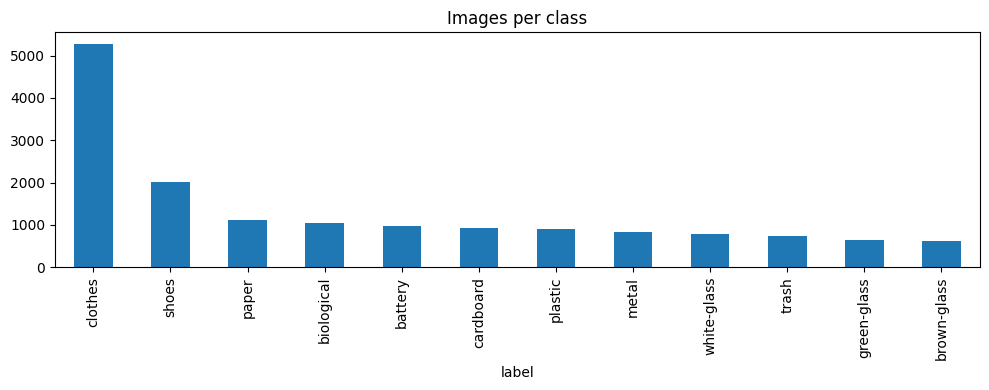

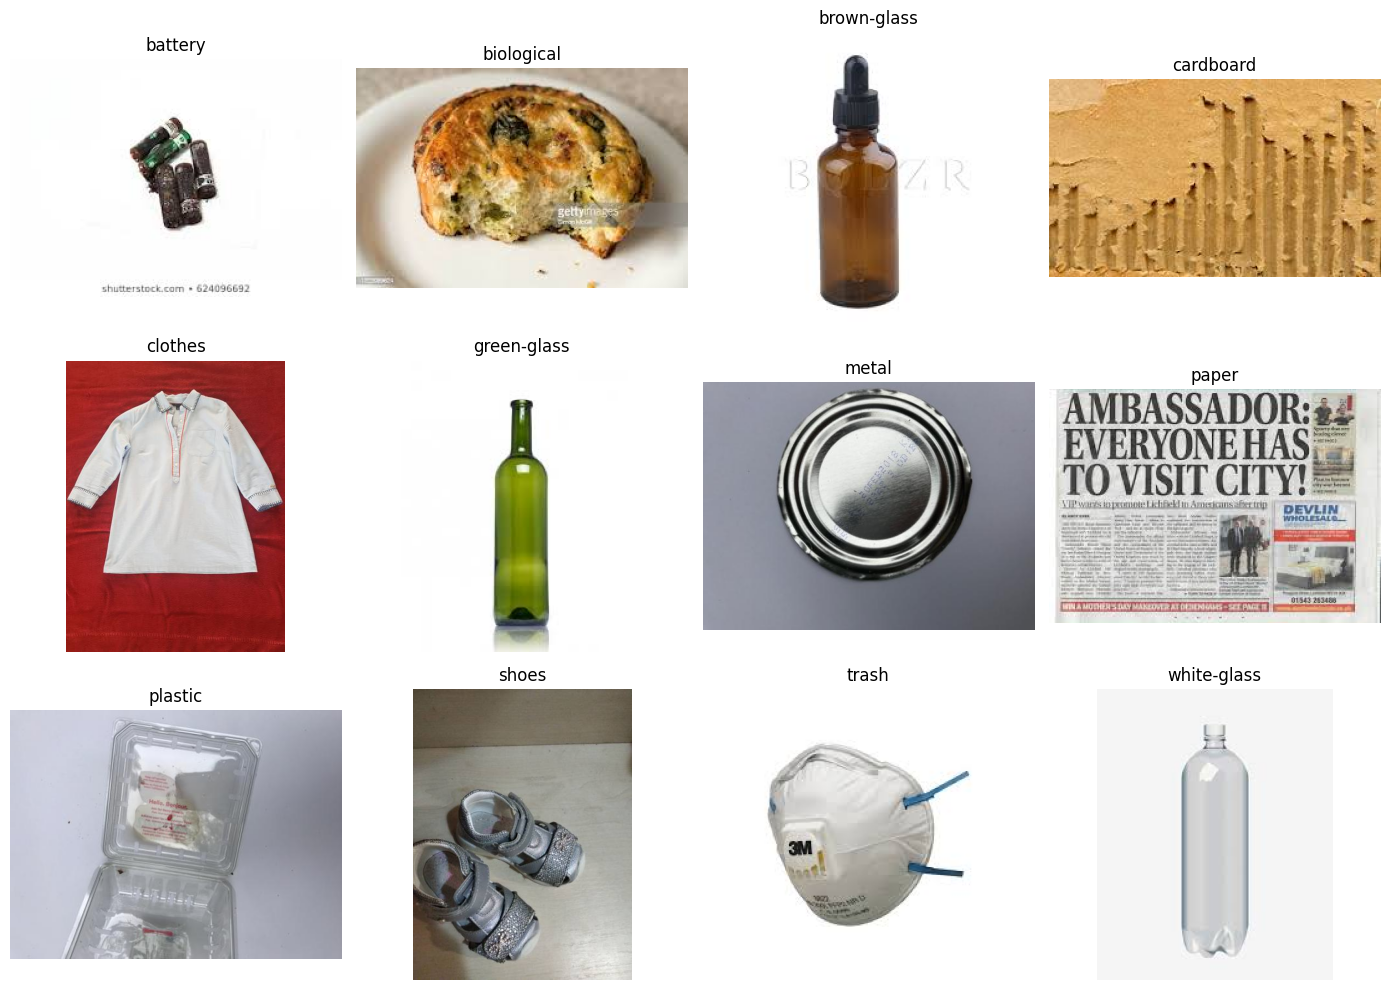

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

df["label"].value_counts().plot(kind="bar", figsize=(10, 4), title="Images per class")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/class_distribution.png", dpi=150)
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, c in zip(axes.flat, class_names):
    f = random.choice(df[df.label == c]["filepath"].tolist())
    ax.imshow(Image.open(f).convert("RGB"))
    ax.set_title(c)
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/samples.png", dpi=150)
plt.show()

In [ ]:
import numpy as np, tensorflow as tf

IMG_SIZE, BATCH = 224, 32
AUTOTUNE = tf.data.AUTOTUNE
label_to_idx = {c: i for i, c in enumerate(class_names)}

def make_ds(d, training):
    ds = tf.data.Dataset.from_tensor_slices(
        (d["filepath"].values, d["label"].map(label_to_idx).values))
    if training:
        ds = ds.shuffle(len(d), seed=42)
    def load(p, y):
        img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        return tf.image.resize(img, (IMG_SIZE, IMG_SIZE)), y
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, True)
val_ds   = make_ds(val_df, False)
test_ds  = make_ds(test_df, False)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.2),
])

base = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)
x = tf.keras.layers.Rescaling(1/127.5, offset=-1)(x)   # scales pixels to [-1, 1], as MobileNetV2 expects
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

y_train = train_df["label"].map(label_to_idx).values
cw = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=y_train)
class_weight = dict(enumerate(cw))
print({class_names[i]: round(w, 2) for i, w in class_weight.items()})

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
{'battery': np.float64(1.35), 'biological': np.float64(1.28), 'brown-glass': np.float64(2.14), 'cardboard': np.float64(1.41), 'clothes': np.float64(0.25), 'green-glass': np.float64(2.06), 'metal': np.float64(1.58), 'paper': np.float64(1.19), 'plastic': np.float64(1.47), 'shoes': np.float64(0.66), 'trash': np.float64(1.82), 'white-glass': np.float64(1.66)}


In [ ]:
import json, keras
SAVE_DIR = "/content/drive/MyDrive/waste_project"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(f"{SAVE_DIR}/model_baseline.keras",
                                       monitor="val_accuracy", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                     restore_best_weights=True),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=12,
                    class_weight=class_weight, callbacks=callbacks)

json.dump(class_names, open(f"{SAVE_DIR}/class_names.json", "w"))
print("TF:", tf.__version__, "| Keras:", keras.__version__)

Epoch 1/12
348/348 ━━━━━━━━━━━━━━━━━━━━ 35s 73ms/step - accuracy: 0.7964 - loss: 0.8276 - val_accuracy: 0.9168 - val_loss: 0.2857
Epoch 2/12
348/348 ━━━━━━━━━━━━━━━━━━━━ 24s 69ms/step - accuracy: 0.8898 - loss: 0.4309 - val_accuracy: 0.9206 - val_loss: 0.2509
Epoch 3/12
348/348 ━━━━━━━━━━━━━━━━━━━━ 42s 72ms/step - accuracy: 0.9080 - loss: 0.3557 - val_accuracy: 0.9315 - val_loss: 0.2312
Epoch 4/12
348/348 ━━━━━━━━━━━━━━━━━━━━ 25s 73ms/step - accuracy: 0.9131 - loss: 0.3357 - val_accuracy: 0.9315 - val_loss: 0.2324
Epoch 5/12
348/348 ━━━━━━━━━━━━━━━━━━━━ 25s 72ms/step - accuracy: 0.9168 - loss: 0.3195 - val_accuracy: 0.9290 - val_loss: 0.2403
Epoch 6/12
348/348 ━━━━━━━━━━━━━━━━━━━━ 25s 72ms/step - accuracy: 0.9220 - loss: 0.3033 - val_accuracy: 0.9374 - val_loss: 0.2136
Epoch 7/12
348/348 ━━━━━━━━━━━━━━━━━━━━ 26s 74ms/step - accuracy: 0.9208 - loss: 0.2983 - val_accuracy: 0.9378 - val_loss: 0.2150
Epoch 8/12
348/348 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.9277 - loss: 0.2757 - 

75/75 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step
              precision    recall  f1-score   support

     battery      0.978     0.918     0.947       147
  biological      0.933     0.994     0.963       155
 brown-glass      0.862     0.871     0.866        93
   cardboard      0.936     0.929     0.932       141
     clothes      0.996     0.997     0.997       793
 green-glass      0.896     0.896     0.896        96
       metal      0.760     0.888     0.819       125
       paper      0.939     0.922     0.930       166
     plastic      0.828     0.822     0.825       135
       shoes      0.990     0.963     0.976       301
       trash      0.954     0.954     0.954       109
 white-glass      0.861     0.782     0.819       119

    accuracy                          0.941      2380
   macro avg      0.911     0.911     0.910      2380
weighted avg      0.943     0.941     0.941      2380



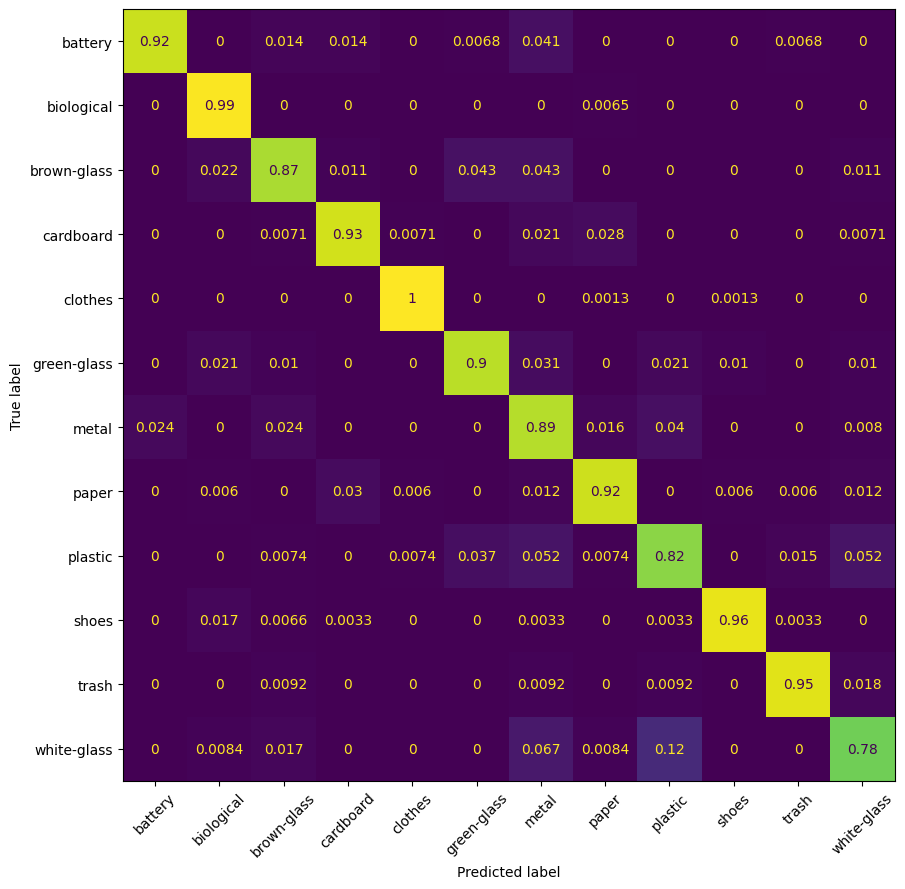

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true = test_df["label"].map(label_to_idx).values
y_pred = model.predict(test_ds).argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names,
                                        normalize="true", xticks_rotation=45,
                                        ax=ax, colorbar=False)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
reloaded = tf.keras.models.load_model(f"{SAVE_DIR}/model_baseline.keras")
loss, acc = reloaded.evaluate(val_ds)
print("val accuracy from saved file:", round(acc, 4))

75/75 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.9408 - loss: 0.2069
val accuracy from saved file: 0.9408


In [1]:
from google.colab import files
up = files.upload()
for name in up:
    img = tf.keras.utils.load_img(name, target_size=(224, 224))
    arr = tf.keras.utils.img_to_array(img)[None]
    p = reloaded.predict(arr, verbose=0)[0]
    top = p.argsort()[::-1][:3]
    print(name, [(class_names[i], round(float(p[i]), 2)) for i in top])

Saving plasticbottle.jpeg to plasticbottle.jpeg


NameError: name 'tf' is not defined

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import tensorflow as tf

SAVE_DIR = "/content/drive/MyDrive/waste_project"
print(os.listdir(SAVE_DIR))

class_names = json.load(open(f"{SAVE_DIR}/class_names.json"))
reloaded = tf.keras.models.load_model(f"{SAVE_DIR}/model_baseline.keras")
print(class_names)

Mounted at /content/drive
['train.csv', 'val.csv', 'test.csv', 'class_distribution.png', 'samples.png', 'model_baseline.keras', 'class_names.json', 'confusion_matrix.png']
['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
